# 03 – Propiedades Dependientes de la Temperatura y Gráficos

Una capacidad calorífica constante es una buena aproximación en una ventana
estrecha de temperatura, pero la combustión, las turbinas de gas y los flujos
reactivos abarcan cientos — incluso miles — de kelvin. En ese régimen, $C_p$,
$S^\circ$ y $H^\circ$ varían fuertemente, y `pyglenn` proporciona su verdadera
dependencia con la temperatura directamente desde los polinomios de la NASA.

En este cuaderno:

1. barremos la temperatura y construimos curvas de propiedades para varios
   gases;
2. leemos la física detrás de las curvas $C_p(T)$ (equipartición y vibraciones);
3. tabulamos los resultados con `pandas`;
4. contrastamos las capacidades caloríficas *instantánea* y *media*; y
5. vemos cómo las fases condensadas tienen rangos de validez más estrechos.

In [1]:
from pyglenn import ThermochemicalCalculator, R

print("Universal gas constant R =", R, "J/(mol.K)")


Universal gas constant R = 8.31446261815324 J/(mol.K)


In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


## 1. Barriendo la temperatura

`calculate_properties_range(id, temps)` evalúa una lista completa de temperaturas de
una sola vez y devuelve un diccionario indexado por temperatura. Lo envolvemos
en un pequeño auxiliar que devuelve arrays listos para graficar, ignorando
cualquier temperatura que esté fuera del rango de validez de la especie (estas
simplemente no aparecen).

In [3]:
SPECIES = ["Ar", "H2", "N2", "O2", "H2O", "CO2", "CH4"]

def curve(calc, name, temps):
    """Devuelve arrays (T, cp, s, h) para las temperaturas que están dentro del rango."""
    sid = calc.get_available_species(name, exact_match=True)[0].id
    props = calc.calculate_properties_range(sid, list(temps))
    T = np.array([p.temperature for p in props])
    cp = np.array([p.cp for p in props])
    s = np.array([p.s for p in props])
    h = np.array([p.h_relative for p in props])
    return T, cp, s, h

temps = np.linspace(300, 3000, 55)
data = {}
with ThermochemicalCalculator() as calc:
    for name in SPECIES:
        data[name] = curve(calc, name, temps)
print("Curvas calculadas para:", ", ".join(data))

Curvas calculadas para: Ar, H2, N2, O2, H2O, CO2, CH4


## 2. Tres curvas de propiedades

$C_p^\circ(T)$, $S^\circ(T)$ y la **entalpía sensible**
$H^\circ(T)-H^\circ(298{,}15\,\mathrm{K})$ (la entalpía necesaria para calentar
la especie desde la temperatura ambiente). Restamos el valor a 298,15 K para que
cada curva comience cerca de cero y las formas sean comparables,
independientemente de la entalpía de formación.

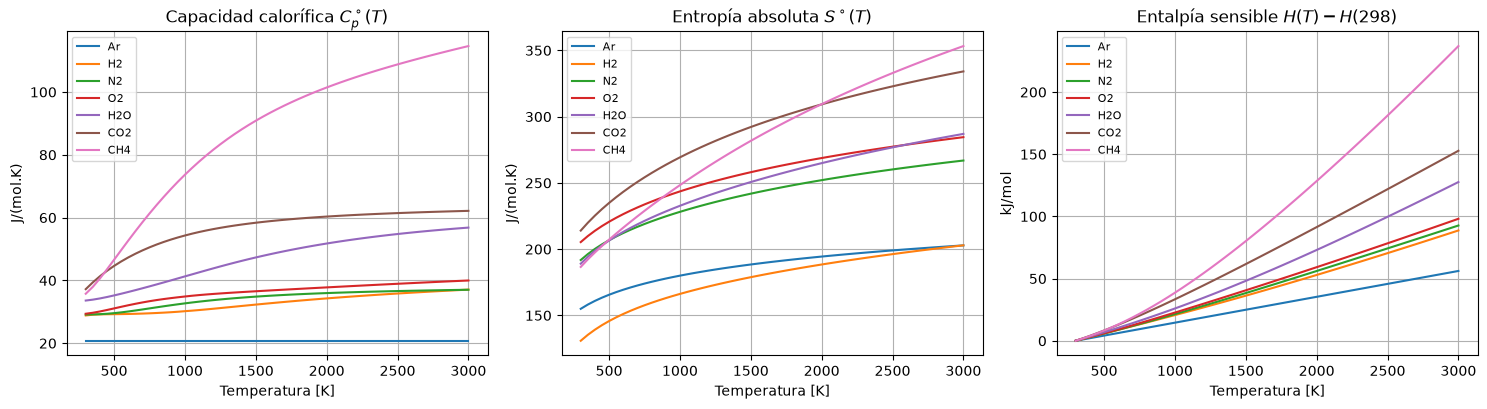

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
with ThermochemicalCalculator() as calc:
    h_ref = {n: calc.calculate_properties(calc.get_available_species(n, exact_match=True)[0].id, 298.15).h_relative
             for n in SPECIES}

for name in SPECIES:
    T, cp, s, h = data[name]
    axes[0].plot(T, cp, label=name)
    axes[1].plot(T, s, label=name)
    axes[2].plot(T, (h - h_ref[name]) / 1000.0, label=name)

axes[0].set_title(r"Capacidad calorífica $C_p^\circ(T)$"); axes[0].set_ylabel("J/(mol.K)")
axes[1].set_title(r"Entropía absoluta $S^\circ(T)$"); axes[1].set_ylabel("J/(mol.K)")
axes[2].set_title("Entalpía sensible $H(T)-H(298)$"); axes[2].set_ylabel("kJ/mol")
for ax in axes:
    ax.set_xlabel("Temperatura [K]"); ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3. Leyendo la física: equipartición

La capacidad calorífica adimensional $C_p/R$ revela la estructura molecular. Por
equipartición, cada grado de libertad cuadrático totalmente activo contribuye con
$\tfrac12 R$ a $C_v$, y para un gas ideal $C_p = C_v + R$:

* **Monoatómico** (Ar): solo 3 modos traslacionales $\Rightarrow C_v=\tfrac32
  R$, luego $C_p=\tfrac52 R$ — constante a todas las temperaturas.
* **Diatómico** (N₂, O₂, H₂): + 2 modos rotacionales $\Rightarrow
  C_p=\tfrac72 R$ a $T$ moderada, subiendo aún más cuando el modo vibracional se
  activa.
* **Poliatómico** (CO₂, H₂O, CH₄): más modos rotacionales y muchos modos
  vibracionales, por lo que $C_p/R$ es mayor y sube pronunciadamente.

Las líneas discontinuas marcan las mesetas $\tfrac52$ y $\tfrac72$.

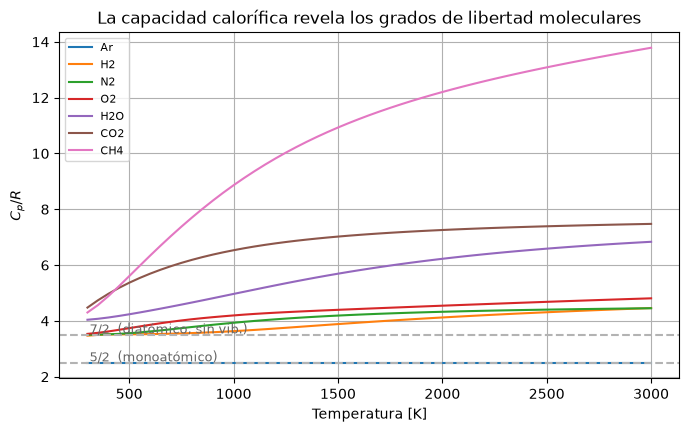

In [5]:
fig, ax = plt.subplots()
for name in SPECIES:
    T, cp, s, h = data[name]
    ax.plot(T, cp / R, label=name)
for level, txt in [(2.5, "5/2  (monoatómico)"), (3.5, "7/2  (diatómico, sin vib.)")]:
    ax.axhline(level, ls="--", color="0.7")
    ax.text(310, level + 0.05, txt, fontsize=9, color="0.4")
ax.set_xlabel("Temperatura [K]")
ax.set_ylabel(r"$C_p / R$")
ax.set_title("La capacidad calorífica revela los grados de libertad moleculares")
ax.legend(fontsize=8)
plt.show()

### Nuevo en 0.3.0: derivada de $C_p$ y razón $C_p/C_v$

`pyglenn` 0.3.0 añadió tres ayudantes de una sola temperatura que resultan
útiles aquí:

* `dcp_dt(id, T)` — la derivada analítica $dC_p/dT$ (en
  J/(mol·K²)), evaluada directamente del polinomio;
* `gamma(id, T)` — la razón de capacidades caloríficas de gas ideal
  $\gamma = C_p/C_v = C_p/(C_p - R)$;
* `h_sensible_to(id, T)` — la entalpía sensible
  $H^\circ(T) - H^\circ(298,15)$ (alias de `calculate_enthalpy_change`).


In [6]:
Tgrid = np.linspace(300, 3000, 6)
with ThermochemicalCalculator() as calc:
    sid = calc.get_available_species("N2", exact_match=True)[0].id
    for T in Tgrid:
        print(f"T={T:6.1f} K  gamma={calc.gamma(sid, T):.4f}  "
              f"dcp_dt={calc.dcp_dt(sid, T):.4f} J/(mol.K^2)  "
              f"h_sensible={calc.h_sensible_to(sid, T)/1000:7.2f} kJ/mol")


T= 300.0 K  gamma=1.3995  dcp_dt=0.0005 J/(mol.K^2)  h_sensible=   0.05 kJ/mol
T= 840.0 K  gamma=1.3555  dcp_dt=0.0066 J/(mol.K^2)  h_sensible=  16.31 kJ/mol
T=1380.0 K  gamma=1.3182  dcp_dt=0.0036 J/(mol.K^2)  h_sensible=  34.25 kJ/mol
T=1920.0 K  gamma=1.3022  dcp_dt=0.0018 J/(mol.K^2)  h_sensible=  53.26 kJ/mol
T=2460.0 K  gamma=1.2942  dcp_dt=0.0010 J/(mol.K^2)  h_sensible=  72.83 kJ/mol
T=3000.0 K  gamma=1.2896  dcp_dt=0.0007 J/(mol.K^2)  h_sensible=  92.71 kJ/mol


## 4. Una tabla de propiedades con pandas

Las tablas discretas siguen siendo útiles para informes. Aquí está $C_p$ en un
conjunto de temperaturas para cada especie, ordenado por el valor a 2000 K para
clasificarlas por cuánta energía absorben cuando se calientan.

In [7]:
table_temps = [300, 600, 1000, 1500, 2000, 2500]
records = {}
with ThermochemicalCalculator() as calc:
    for name in SPECIES:
        sid = calc.get_available_species(name, exact_match=True)[0].id
        records[name] = {f"{t} K": calc.calculate_properties(sid, t).cp
                         for t in table_temps}

cp_df = pd.DataFrame(records).T.sort_values("2000 K", ascending=False)
cp_df.index.name = "especie"
print("Cp [J/(mol.K)]")
print(cp_df.to_string())

Cp [J/(mol.K)]
         300 K  600 K  1000 K  1500 K  2000 K  2500 K
especie                                              
CH4     35.760 52.691  73.676  90.866 101.443 108.790
CO2     37.220 47.323  54.309  58.374  60.335  61.443
H2O     33.596 36.324  41.291  47.318  51.756  54.777
O2      29.388 32.090  34.883  36.553  37.784  38.933
N2      29.125 30.109  32.696  34.842  35.970  36.615
H2      28.849 29.318  30.206  32.305  34.276  35.832
Ar      20.786 20.786  20.786  20.786  20.786  20.786


## 5. Capacidad calorífica instantánea vs. media

Dos capacidades caloríficas aparecen en cálculos de ingeniería:

* la **instantánea** $C_p(T) = \left(\partial H/\partial T\right)_p$;
* la **media** $\overline{C_p}\big|_{T_1}^{T_2} = \dfrac{H(T_2)-H(T_1)}{T_2-T_1}$,
  que es la que realmente se multiplica por $\Delta T$ para obtener un cambio de
  entalpía.

Usando `calculate_enthalpy_change` para el numerador, comparamos ambas para el
nitrógeno. La media (desde 300 K) va por debajo del valor instantáneo porque
promedia la región más fría, de menor $C_p$.

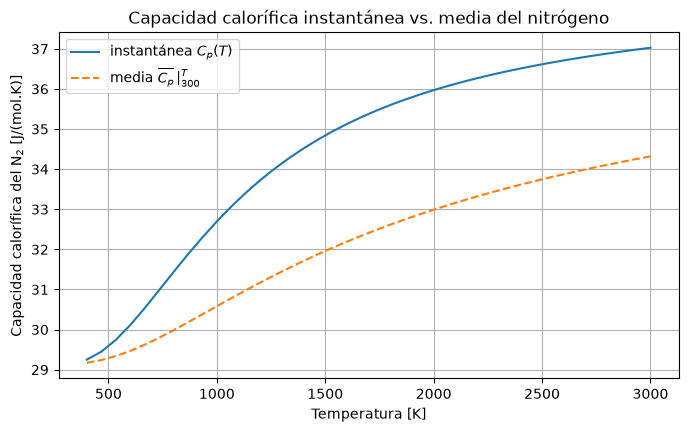

In [8]:
T2 = np.linspace(400, 3000, 40)
with ThermochemicalCalculator() as calc:
    n2 = calc.get_available_species("N2", exact_match=True)[0].id
    cp_inst = np.array([calc.calculate_properties(n2, t).cp for t in T2])
    cp_mean = np.array([calc.calculate_enthalpy_change(n2, 300.0, t) / (t - 300.0)
                        for t in T2])

fig, ax = plt.subplots()
ax.plot(T2, cp_inst, label=r"instantánea $C_p(T)$")
ax.plot(T2, cp_mean, "--", label=r"media $\overline{C_p}\,|_{300}^{T}$")
ax.set_xlabel("Temperatura [K]")
ax.set_ylabel("Capacidad calorífica del N$_2$ [J/(mol.K)]")
ax.set_title("Capacidad calorífica instantánea vs. media del nitrógeno")
ax.legend()
plt.show()

## 6. Las fases condensadas tienen rangos más estrechos

Los ajustes para fase gaseosa típicamente cubren 200–6000 K, pero los líquidos y
sólidos solo son válidos en una ventana pequeña. Solicitar una temperatura fuera
de esa ventana lanza un `TemperatureOutOfRangeError` — captúrelo con
`try/except`. El agua líquida es un buen ejemplo.

In [9]:
from pyglenn import TemperatureOutOfRangeError

with ThermochemicalCalculator() as calc:
    liq = calc.get_available_species("H2O(L)", exact_match=True)[0].id
    data_liq = calc.db.get_species_data(liq)
    ranges = [(iv.temp_min, iv.temp_max) for iv in data_liq.intervals]
    print("H2O(L) intervalo(s) válido(s):", ranges)
    for T in [350.0, 2000.0]:
        try:
            p = calc.calculate_properties(liq, T)
            print(f"  T = {T:7.1f} K  ->  Cp = {p.cp:.2f} J/(mol.K)")
        except TemperatureOutOfRangeError:
            print(f"  T = {T:7.1f} K  ->  fuera de rango")

H2O(L) intervalo(s) válido(s): [(273.15, 373.15), (373.15, 600.0)]
  T =   350.0 K  ->  Cp = 75.53 J/(mol.K)
  T =  2000.0 K  ->  fuera de rango


## Resumen

- `calculate_properties_range` barre muchas temperaturas en una sola llamada.
- La forma de $C_p/R$ refleja directamente los grados de libertad traslacionales,
  rotacionales y vibracionales.
- $C_p$ media e instantánea son diferentes — use la media (vía
  `calculate_enthalpy_change`) para $\Delta T$ finito.
- Siempre maneje `None` para temperaturas fuera de rango, especialmente en fases
  condensadas.

**A continuación:** el cuaderno 04 extrae entalpías de formación de estos mismos
polinomios.